# Hillstrom email experiment: revenue and targeting

Independent educational reanalysis of Kevin Hillstrom's historical, already-solved public benchmark. This is not a new experiment or an original discovery of its headline result.

**Business questions:** Does either email increase mean two-week revenue per assigned customer? Can a capacity-constrained targeting policy improve on a uniformly random Mens mailing?

The author's reported design randomly assigned 64,000 customers in thirds to Mens E-Mail, Womens E-Mail and No E-Mail. Each row is treated as one customer, as documented by the publisher. Actual customer identity and the original randomization implementation cannot be verified from this file.

**Final result:** both campaign-versus-control revenue comparisons are positive on the full sample. The validation-selected high-history policy did not establish a clear advantage on the independent test set: its approximate intervals include zero against both no email and random Mens.

The order below preserves the analysis workflow: structural checks; fixed split; development analyses; validation policy selection; locked test evaluation; then full-sample campaign estimates. Validation was part of development exploration. Test outcomes were reserved until the policy and its comparisons were fixed.

Original description: https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html

Read analysis_plan.md and docs/decision_log.md for the original plan and implementation decisions.


In [1]:
from pathlib import Path
import hashlib
import pandas as pd

DATA_PATH = Path("data/raw/hillstrom.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == "00a6a868e05a9ffe7382da51629f6d6dce88c5acfc945e79d314ebc78fd3a2c0"
email = pd.read_csv(DATA_PATH)
display(email.head())
print(email.shape)

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


(64000, 12)


## Data contract and missingness

There is no customer-ID field. Fully matching rows identify repeated recorded combinations, not proven duplicate people. Do not automatically deduplicate these records. The source-described unit is a customer; dependence from unidentified repeat people remains a limitation.

The assignment field is segment. Outcomes are visit, conversion and spend. All remaining fields describe the period before assignment.


In [2]:
display(email.dtypes)
display(email.isna().sum())
display(email["segment"].value_counts(dropna=False))
print("Extra fully matching rows:", email.duplicated().sum())
print("Locality categories:", email["zip_code"].unique())
print("Prior purchase channels:", email["channel"].unique())

recency              int64
history_segment        str
history            float64
mens                 int64
womens               int64
zip_code               str
newbie               int64
channel                str
segment                str
visit                int64
conversion           int64
spend              float64
dtype: object

recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0
dtype: int64

segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

Extra fully matching rows: 6562
Locality categories: <StringArray>
['Surburban', 'Rural', 'Urban']
Length: 3, dtype: str
Prior purchase channels: <StringArray>
['Phone', 'Web', 'Multichannel']
Length: 3, dtype: str


### Working copy and category normalization

Preserve the input and normalize the exact category spelling Surburban to Suburban in a working copy. Keep all 64,000 rows. The frequency table is a diagnostic, not a replacement for the customer-level data.


In [3]:
email_clean = email.copy()

email_clean["zip_code"] = email_clean["zip_code"].replace(
    {"Surburban": "Suburban"}
)

profiles = (
    email_clean.value_counts(dropna=False)
    .reset_index(name="rows")
)

display(profiles.head(10))

,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend,rows
0,10,1) $0 - $100,29.99,0,1,Suburban,1,Phone,Mens E-Mail,0,0,0.0,31
1,10,1) $0 - $100,29.99,1,0,Suburban,0,Phone,No E-Mail,0,0,0.0,27
2,10,1) $0 - $100,29.99,1,0,Suburban,0,Web,Womens E-Mail,0,0,0.0,27
3,10,1) $0 - $100,29.99,0,1,Urban,1,Phone,Womens E-Mail,0,0,0.0,27
4,10,1) $0 - $100,29.99,1,0,Suburban,1,Web,No E-Mail,0,0,0.0,26
5,10,1) $0 - $100,29.99,1,0,Suburban,1,Phone,No E-Mail,0,0,0.0,26
6,10,1) $0 - $100,29.99,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0,25
7,10,1) $0 - $100,29.99,0,1,Urban,0,Web,Womens E-Mail,0,0,0.0,25
8,9,1) $0 - $100,29.99,1,0,Suburban,1,Web,No E-Mail,0,0,0.0,25
9,10,1) $0 - $100,29.99,0,1,Suburban,1,Web,Mens E-Mail,0,0,0.0,25


### Value ranges

Check that binary fields contain 0/1, recency is in its documented monthly range, and monetary fields are nonnegative. Integer-encoded binary outcomes do not require conversion to strings.


In [4]:
binary_columns = ["mens", "womens", "newbie", "visit", "conversion"]

for column in binary_columns:
    print(column, sorted(email_clean[column].unique()))

display(
    email_clean[["recency", "history", "spend"]]
    .agg(["min", "max"])
)

mens [np.int64(0), np.int64(1)]
womens [np.int64(0), np.int64(1)]
newbie [np.int64(0), np.int64(1)]
visit [np.int64(0), np.int64(1)]
conversion [np.int64(0), np.int64(1)]


,recency,history,spend
min,1,29.99,0.0
max,12,3345.93,499.0


### Outcome coherence

Count purchases without visits, positive spend without conversion, and conversion without positive spend. These diagnostics are zero in this file. Genuine zero outcomes remain in all per-assigned-customer means.


In [5]:
bought = email_clean["conversion"] == 1
visited = email_clean["visit"] == 1
positive_spend = email_clean["spend"] > 0
checks = pd.Series({
    "Purchase without visit": (bought & ~visited).sum(),
    "Positive spend without purchase": (positive_spend & ~bought).sum(),
    "Purchase with zero spend": (bought & ~positive_spend).sum()
})
display(checks)

Purchase without visit             0
Positive spend without purchase    0
Purchase with zero spend           0
dtype: int64

## Allocation and pretreatment balance

Test the author's stated 1:1:1 allocation with a chi-square sample-ratio-mismatch diagnostic. The prespecified flag threshold is 0.001. A large p-value indicates no detected allocation-count discrepancy; it does not establish all aspects of experiment validity.


In [6]:
from scipy.stats import chisquare

group_sizes = email_clean["segment"].value_counts()
expected_size = len(email_clean) / 3

srm_stat, srm_p = chisquare(
    f_obs=group_sizes,
    f_exp=[expected_size] * 3
)

display(group_sizes)
print(f"Expected group size: {expected_size:.2f}")
print(f"SRM p-value: {srm_p:.6f}")

segment
Womens E-Mail    21387
Mens E-Mail      21307
No E-Mail        21306
Name: count, dtype: int64

Expected group size: 21333.33
SRM p-value: 0.903693


### Pretreatment means

Mean binary fields are proportions. The mens and womens fields indicate past merchandise-category purchases, not customer gender. The channel field describes previous purchasing channels, not email delivery.


In [7]:
balance_columns = [
    "recency", "history", "mens", "womens", "newbie"
]

balance = (
    email_clean
    .groupby("segment")[balance_columns]
    .mean()
)

display(balance.round(3))

,recency,history,mens,womens,newbie
segment,,,,,
Mens E-Mail,5.774,242.836,0.551,0.551,0.502
No E-Mail,5.750,240.883,0.553,0.548,0.502
Womens E-Mail,5.768,242.537,0.549,0.550,0.503


### Pretreatment category proportions

Compare the composition of the assignment groups. Row-normalized crosstabs report percentages within each assignment group. The zip_code field is a locality category, not a numeric postal code.


In [8]:
for column in ["zip_code", "channel", "history_segment"]:
    print(column)

    shares = pd.crosstab(
        email_clean["segment"],
        email_clean[column],
        normalize="index"
    )

    display(shares.mul(100).round(2))

zip_code


zip_code,Rural,Suburban,Urban
segment,,,
Mens E-Mail,15.22,44.59,40.19
No E-Mail,14.73,45.18,40.09
Womens E-Mail,14.87,45.12,40.01


channel


channel,Multichannel,Phone,Web
segment,,,
Mens E-Mail,12.09,43.37,44.54
No E-Mail,12.23,43.78,43.99
Womens E-Mail,12.06,44.20,43.74


history_segment


history_segment,1) $0 - $100,2) $100 - $200,3) $200 - $350,4) $350 - $500,5) $500 - $750,"6) $750 - $1,000","7) $1,000 +"
segment,,,,,,,
Mens E-Mail,36.25,22.02,19.20,9.84,7.50,3.02,2.18
No E-Mail,35.73,22.70,18.98,9.97,7.75,2.92,1.95
Womens E-Mail,35.69,22.10,19.43,10.23,7.77,2.77,2.00


### Standardized mean differences

For each campaign versus control, divide the difference of pretreatment means by the square root of the average group variances. These are effect-size diagnostics, not evidence that unobserved characteristics or customer identities are balanced.


In [9]:
variances = (
    email_clean
    .groupby("segment")[balance_columns]
    .var()
)

smd = pd.DataFrame(index=balance_columns)

for group in ["Mens E-Mail", "Womens E-Mail"]:
    pooled_sd = (
        (variances.loc[group] + variances.loc["No E-Mail"]) / 2
    ) ** 0.5

    smd[group] = (
        balance.loc[group] - balance.loc["No E-Mail"]
    ) / pooled_sd

display(smd.round(3))

,Mens E-Mail,Womens E-Mail
recency,0.007,0.005
history,0.008,0.007
mens,-0.005,-0.009
womens,0.008,0.005
newbie,-0.001,0.003


## Fixed train / validation / test split

Before comparing outcome effects, reserve 20% as test with seed 42, then 25% of the remainder as validation with seed 43. Both splits stratify on assignment: train 38,400, validation 12,800, test 12,800.

Train plus validation (51,200 rows) is the development set for interim inference, outcome exploration and segment discovery. Models fit only the train rows; validation selects policies. Test outcomes are excluded from policy selection. Row indices below identify source-file records, not persistent customer IDs.


In [10]:
from sklearn.model_selection import train_test_split

train_val, test = train_test_split(
    email_clean,
    test_size=0.20,
    random_state=42,
    stratify=email_clean["segment"]
)

train, validation = train_test_split(
    train_val,
    test_size=0.25,
    random_state=43,
    stratify=train_val["segment"]
)

print("Train:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))

Train: 38400
Validation: 12800
Test: 12800


## Development outcomes (51,200 customers)

The primary outcome is two-week mean spend per assigned customer, including zeros. Visits and conversions are secondary. Per-customer revenue uses every customer as its denominator.


In [11]:
group_summary = train_val.groupby("segment").agg(
    customers=("segment", "size"),
    visit_rate_pct=("visit", "mean"),
    conversion_rate_pct=("conversion", "mean"),
    revenue_per_customer=("spend", "mean")
)

percent_columns = ["visit_rate_pct", "conversion_rate_pct"]
group_summary[percent_columns] = (
    group_summary[percent_columns] * 100
)

display(group_summary.round(2))

,customers,visit_rate_pct,conversion_rate_pct,revenue_per_customer
segment,,,,
Mens E-Mail,17045,18.43,1.24,1.46
No E-Mail,17045,10.73,0.52,0.64
Womens E-Mail,17110,15.17,0.88,1.07


### Absolute and relative revenue differences

Subtract the no-email mean for the absolute dollar difference. Divide that difference by the control mean for the relative percentage change. Use unrounded values for calculations.


In [12]:
control_revenue = group_summary.loc[
    "No E-Mail", "revenue_per_customer"
]

revenue = group_summary.loc[
    ["Mens E-Mail", "Womens E-Mail"],
    "revenue_per_customer"
]

revenue_effects = pd.DataFrame({
    "revenue_per_customer": revenue,
    "absolute_effect": revenue - control_revenue,
    "relative_effect_pct": (
        (revenue - control_revenue) / control_revenue * 100
    )
})

display(revenue_effects.round(2))

,revenue_per_customer,absolute_effect,relative_effect_pct
segment,,,
Mens E-Mail,1.46,0.83,130.13
Womens E-Mail,1.07,0.43,67.33


### Interim campaign-versus-control inference

Use two-sided Welch tests and ordinary, separate 95% confidence intervals for the two primary revenue contrasts. Holm adjusts their p-values as a two-comparison family at 0.05. These development results are interim; the final fixed-sample campaign estimates appear after policy evaluation.


In [13]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

control_spend = train_val.loc[
    train_val["segment"] == "No E-Mail", "spend"
]

rows = []

for group in ["Mens E-Mail", "Womens E-Mail"]:
    treatment_spend = train_val.loc[
        train_val["segment"] == group, "spend"
    ]

    result = ttest_ind(
        treatment_spend,
        control_spend,
        equal_var=False,
        alternative="two-sided"
    )
    interval = result.confidence_interval(confidence_level=0.95)

    rows.append({
        "group": group,
        "effect": treatment_spend.mean() - control_spend.mean(),
        "ci_low": interval.low,
        "ci_high": interval.high,
        "p_raw": result.pvalue
    })

revenue_tests = pd.DataFrame(rows).set_index("group")

revenue_tests["p_holm"] = multipletests(
    revenue_tests["p_raw"], alpha=0.05, method="holm"
)[1]

display(revenue_tests)

,effect,ci_low,ci_high,p_raw,p_holm
group,,,,,
Mens E-Mail,0.828370,0.504724,1.152016,5.286600e-07,0.000001
Womens E-Mail,0.428626,0.143191,0.714062,3.249598e-03,0.003250


### Bootstrap sensitivity of development intervals

Independently resample the campaign and control arrays with replacement, preserving their sizes. Use 10,000 replicates and seed 42, saving only mean differences. The 2.5% and 97.5% quantiles give separate percentile intervals. This uses the same data as Welch and is not an independent replication.


In [14]:
import numpy as np

def bootstrap_diff_ci(treatment, control, n_boot=10_000, seed=42):
    rng = np.random.default_rng(seed)
    treatment = treatment.to_numpy()
    control = control.to_numpy()
    differences = []

    for _ in range(n_boot):
        t_sample = rng.choice(
            treatment, size=len(treatment), replace=True
        )
        c_sample = rng.choice(
            control, size=len(control), replace=True
        )

        differences.append(t_sample.mean() - c_sample.mean())

    return np.quantile(differences, [0.025, 0.975])


bootstrap_check = revenue_tests[["effect", "ci_low", "ci_high"]].copy()

for group in ["Mens E-Mail", "Womens E-Mail"]:
    treatment_spend = train_val.loc[
        train_val["segment"] == group, "spend"
    ]

    low, high = bootstrap_diff_ci(treatment_spend, control_spend)

    bootstrap_check.loc[group, "boot_low"] = low
    bootstrap_check.loc[group, "boot_high"] = high

display(bootstrap_check.round(3))

,effect,ci_low,ci_high,boot_low,boot_high
group,,,,,
Mens E-Mail,0.828,0.505,1.152,0.509,1.158
Womens E-Mail,0.429,0.143,0.714,0.146,0.714


### Development effect figure

The dots are campaign-minus-control revenue estimates. Error bars are individual 95% Welch intervals, not simultaneous intervals for the family.


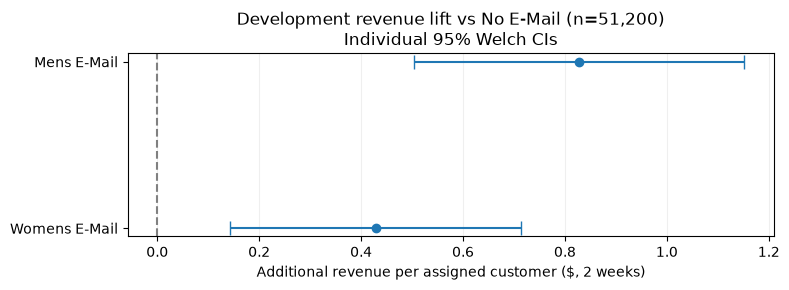

In [15]:
import matplotlib.pyplot as plt

effect = revenue_tests["effect"]

errors = [
    effect - revenue_tests["ci_low"],
    revenue_tests["ci_high"] - effect
]

fig, ax = plt.subplots(figsize=(8, 3))

ax.errorbar(
    effect,
    revenue_tests.index,
    xerr=errors,
    fmt="o",
    capsize=5
)

ax.axvline(0, color="gray", linestyle="--")
ax.invert_yaxis()
ax.set_title("Development revenue lift vs No E-Mail (n=51,200)\nIndividual 95% Welch CIs")
ax.set_xlabel("Additional revenue per assigned customer ($, 2 weeks)")
ax.grid(axis="x", alpha=0.2)

fig.tight_layout()
fig.savefig("outputs/development_revenue_effects.png", dpi=200, bbox_inches="tight")
plt.show()

## Secondary exploratory comparisons

The prespecified secondary family has seven tests: each campaign versus control on visit and conversion (four); Mens versus Womens on revenue, visit and conversion (three). First collect the direct revenue comparison; its raw p-value is not a final family decision.


In [16]:
mens_spend = train_val.loc[
    train_val["segment"] == "Mens E-Mail", "spend"
]
womens_spend = train_val.loc[
    train_val["segment"] == "Womens E-Mail", "spend"
]

result = ttest_ind(
    mens_spend,
    womens_spend,
    equal_var=False,
    alternative="two-sided"
)
interval = result.confidence_interval(confidence_level=0.95)

secondary_revenue = pd.DataFrame([{
    "comparison": "Mens vs Womens",
    "metric": "spend",
    "effect": mens_spend.mean() - womens_spend.mean(),
    "unit": "USD",
    "ci_low": interval.low,
    "ci_high": interval.high,
    "p_raw": result.pvalue
}])

display(secondary_revenue)

,comparison,metric,effect,unit,ci_low,ci_high,p_raw
0,Mens vs Womens,spend,0.399744,USD,0.047562,0.751926,0.026106


### Complete secondary family

Use two-sided two-proportion z-tests for binary outcomes and Newcombe intervals for differences in proportions. Convert proportion differences to percentage points. Apply Benjamini-Hochberg at q=0.05 across all seven p-values.

This is a separate exploratory FDR analysis under the method's dependence assumptions, not global 5% family-wise error control across the project. Intervals remain individual 95% intervals.


In [17]:
from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)

pairs = [
    ("Mens E-Mail", "No E-Mail", "Mens vs Control"),
    ("Womens E-Mail", "No E-Mail", "Womens vs Control"),
    ("Mens E-Mail", "Womens E-Mail", "Mens vs Womens")
]

binary_rows = []

for group_a, group_b, label in pairs:
    for metric in ["visit", "conversion"]:
        a = train_val.loc[train_val["segment"] == group_a, metric]
        b = train_val.loc[train_val["segment"] == group_b, metric]

        _, p_value = proportions_ztest(
            count=[a.sum(), b.sum()],
            nobs=[len(a), len(b)],
            alternative="two-sided"
        )

        low, high = confint_proportions_2indep(
            count1=a.sum(), nobs1=len(a),
            count2=b.sum(), nobs2=len(b),
            method="newcomb",
            compare="diff",
            alpha=0.05
        )

        binary_rows.append({
            "comparison": label,
            "metric": metric,
            "effect": (a.mean() - b.mean()) * 100,
            "unit": "pp",
            "ci_low": low * 100,
            "ci_high": high * 100,
            "p_raw": p_value
        })

secondary_tests = pd.concat(
    [secondary_revenue, pd.DataFrame(binary_rows)],
    ignore_index=True
)

secondary_tests["p_bh"] = multipletests(
    secondary_tests["p_raw"],
    alpha=0.05,
    method="fdr_bh"
)[1]

display(secondary_tests.round({
    "effect": 3, "ci_low": 3, "ci_high": 3
}))

,comparison,metric,effect,unit,ci_low,ci_high,p_raw,p_bh
0,Mens vs Womens,spend,0.400,USD,0.048,0.752,2.610564e-02,2.610564e-02
1,Mens vs Control,visit,7.703,pp,6.958,8.448,2.708684e-90,1.896079e-89
2,Mens vs Control,conversion,0.727,pp,0.531,0.930,6.438737e-13,1.126779e-12
3,Womens vs Control,visit,4.442,pp,3.731,5.153,2.345408e-34,8.208929e-34
4,Womens vs Control,conversion,0.366,pp,0.190,0.546,4.908381e-05,6.871733e-05
5,Mens vs Womens,visit,3.261,pp,2.469,4.053,7.610634e-16,1.775815e-15
6,Mens vs Womens,conversion,0.361,pp,0.144,0.581,1.132810e-03,1.321612e-03


### Descriptive revenue decomposition

Revenue per assigned customer equals the purchase proportion times mean spend per buyer, since nonbuyers have zero spend. Spend per buyer is descriptive: buyers are a post-treatment-selected group whose composition can change. This is not average order value; the file has no order count.


In [18]:
buyers = train_val.loc[train_val["conversion"] == 1]

revenue_breakdown = pd.DataFrame({
    "conversion_rate_pct": group_summary["conversion_rate_pct"],
    "spend_per_buyer": buyers.groupby("segment")["spend"].mean(),
    "revenue_per_customer": group_summary["revenue_per_customer"]
})

display(revenue_breakdown.round(2))

,conversion_rate_pct,spend_per_buyer,revenue_per_customer
segment,,,
Mens E-Mail,1.24,117.78,1.46
No E-Mail,0.52,123.30,0.64
Womens E-Mail,0.88,120.70,1.07


### Positive-spend distribution

Inspect buyer counts, quantiles and maxima to understand the upper tail. Quantiles here describe customer spend values, not confidence bounds.


In [19]:
spend_distribution = (
    buyers.groupby("segment")["spend"]
    .describe(percentiles=[0.50, 0.90, 0.95, 0.99])
)

display(
    spend_distribution[
        ["count", "50%", "90%", "95%", "99%", "max"]
    ].round(2)
)


,count,50%,90%,95%,99%,max
segment,,,,,,
Mens E-Mail,212.0,70.06,276.07,381.20,499.00,499.0
No E-Mail,88.0,92.49,247.24,377.27,451.95,499.0
Womens E-Mail,151.0,98.26,271.51,329.86,499.00,499.0


### Exploratory upper-tail sensitivity

Cap spend at the pooled development buyers' 95th percentile, using one common threshold for all arms. Keep all rows and zeros. This changes the outcome to capped revenue and is a descriptive sensitivity calculation, not a replacement for the primary full-revenue estimand. The threshold and method were fixed before viewing capped effects.


In [20]:
cap = buyers["spend"].quantile(0.95)

sensitivity_data = train_val.copy()
sensitivity_data["spend_capped"] = (
    sensitivity_data["spend"].clip(upper=cap)
)

capped_means = (
    sensitivity_data.groupby("segment")["spend_capped"].mean()
)

sensitivity = pd.DataFrame({
    "original_effect": revenue_tests["effect"],
    "capped_effect": (
        capped_means.loc[revenue_tests.index]
        - capped_means.loc["No E-Mail"]
    )
})

sensitivity["change"] = (
    sensitivity["capped_effect"] - sensitivity["original_effect"]
)

print(f"Shared cap (USD): {cap:.2f}")
print("Capped amounts:", (train_val["spend"] > cap).sum())
display(sensitivity.round(3))

Shared cap (USD): 362.72
Capped amounts: 23


,original_effect,capped_effect,change
group,,,
Mens E-Mail,0.828,0.796,-0.032
Womens E-Mail,0.429,0.416,-0.013


## Additional regression adjustment

Fit an additive linear model of full, uncapped spend on assigned campaign indicators and pretreatment history. The no-email group is the reference. HC3 standard errors allow heteroskedastic residuals. Compare estimates and interval widths with the unadjusted development analysis; do not select a method by whichever p-value is smaller.


In [21]:
import statsmodels.formula.api as smf

adjustment_data = train_val.copy()

adjustment_data["mens_email"] = (
    adjustment_data["segment"] == "Mens E-Mail"
).astype(int)

adjustment_data["womens_email"] = (
    adjustment_data["segment"] == "Womens E-Mail"
).astype(int)

adjusted_model = smf.ols(
    "spend ~ mens_email + womens_email + history",
    data=adjustment_data
).fit(cov_type="HC3")

terms = ["mens_email", "womens_email"]
intervals = adjusted_model.conf_int(alpha=0.05).loc[terms]

adjusted_results = pd.DataFrame({
    "adj_effect": adjusted_model.params.loc[terms],
    "adj_ci_low": intervals[0],
    "adj_ci_high": intervals[1]
})

adjusted_results.index = ["Mens E-Mail", "Womens E-Mail"]

adjusted_comparison = revenue_tests[
    ["effect", "ci_low", "ci_high"]
].join(adjusted_results)

display(adjusted_comparison.round(3))

,effect,ci_low,ci_high,adj_effect,adj_ci_low,adj_ci_high
group,,,,,,
Mens E-Mail,0.828,0.505,1.152,0.823,0.500,1.147
Womens E-Mail,0.429,0.143,0.714,0.423,0.139,0.708


## Prespecified coarse segment exploration

Before viewing segment effects, fix three binary splits: newbie; recency 1-6 versus 7-12 months; history at most USD 200 versus above USD 200. Examine cell sizes and buyers as well as revenue. Effects compare each campaign with control within the same segment.


In [22]:
heterogeneity_data = adjustment_data.copy()

heterogeneity_data["recent_buyer"] = (
    heterogeneity_data["recency"] <= 6
).astype(int)

heterogeneity_data["high_history"] = (
    heterogeneity_data["history"] > 200
).astype(int)

newbie_summary = (
    heterogeneity_data.groupby(["newbie", "segment"])
    .agg(
        customers=("spend", "size"),
        buyers=("conversion", "sum"),
        revenue_per_customer=("spend", "mean")
    )
)

display(newbie_summary.round(3))

customers  buyers  revenue_per_customer
newbie segment                                               
0      Mens E-Mail         8483     117                 1.492
       No E-Mail           8481      58                 0.938
       Womens E-Mail       8542      75                 1.067
1      Mens E-Mail         8562      95                 1.438
       No E-Mail           8564      30                 0.338
       Womens E-Mail       8568      76                 1.063

### Omnibus interaction tests

For each of the three pretreatment features, jointly test its two campaign-interaction coefficients using HC3 covariance. Holm adjusts these three exploratory tests at 0.05. No feature passes that threshold. This leaves uncertainty about heterogeneity rather than proving effects equal.


In [23]:
interaction_rows = []
interaction_models = {}

for feature in ["newbie", "recent_buyer", "high_history"]:
    model = smf.ols(
        f"spend ~ (mens_email + womens_email) * {feature}",
        data=heterogeneity_data
    ).fit(cov_type="HC3")

    joint_test = model.f_test(
        f"mens_email:{feature} = 0, "
        f"womens_email:{feature} = 0"
    )

    interaction_rows.append({
        "feature": feature,
        "p_raw": float(joint_test.pvalue)
    })

    interaction_models[feature] = model

interaction_tests = pd.DataFrame(
    interaction_rows
).set_index("feature")

interaction_tests["p_holm"] = multipletests(
    interaction_tests["p_raw"],
    alpha=0.05,
    method="holm"
)[1]

display(interaction_tests)

,p_raw,p_holm
feature,,
newbie,0.074025,0.195020
recent_buyer,0.369164,0.369164
high_history,0.065007,0.195020


## Capacity-constrained policy learning

The mailing capacity is an illustrative business scenario, not a fact supplied with the historical data: at most 10,000 of 64,000 customers (15.625%). This corresponds to 2,000 of 12,800 on validation and test.

Use only seven pretreatment inputs. Omit history_segment because history already represents past spend numerically. Never include visit, conversion or spend as policy features.


In [24]:
feature_columns = [
    "recency", "history", "mens", "womens",
    "newbie", "zip_code", "channel"
]

X_train = train[feature_columns].copy()
X_val = validation[feature_columns].copy()

y_train = train["spend"]
y_val = validation["spend"]

assignment_train = train["segment"]
assignment_val = validation["segment"]

capacity_fraction = 10_000 / 64_000
val_capacity = int(len(validation) * capacity_fraction)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Validation mailing capacity:", val_capacity)

Train: (38400, 7)
Validation: (12800, 7)
Validation mailing capacity: 2000


### Off-policy evaluation

Only the assigned action's outcome is observed. IPW uses matched recommendations and inverse assignment weights to estimate mean policy revenue over all eligible customers.

For the conditional evaluation on the assignment-stratified split, use its fixed allocation fractions n_arm / N, close to the nominal 1/3. These are allocation weights, not a propensity model learned from customer outcomes. Arrays must preserve the same row order.


In [25]:
def ipw_scores(policy, assignment, revenue):
    allocation = assignment.value_counts(normalize=True)
    probabilities = assignment.map(allocation).to_numpy()
    matched = np.asarray(policy) == assignment.to_numpy()

    return matched * revenue.to_numpy() / probabilities

### Expected uniformly random mailing benchmarks

Uniformly choose exactly K recipients and give all of them the same campaign. Each customer's marginal mailing probability is q=K/N. Average analytically over recipient lotteries: q times the all-campaign score plus (1-q) times the no-email score.

This removes noise from an arbitrary recipient lottery while retaining sampling uncertainty about outcomes. It does not require independent Bernoulli mailing decisions or exceed the fixed capacity. No-email revenue can be positive because customers can purchase without a message.


In [26]:
no_email = np.full(len(X_val), "No E-Mail", dtype=object)
no_email_scores = ipw_scores(no_email, assignment_val, y_val)
q = val_capacity / len(X_val)

reference_scores = {"No email": no_email_scores}

for action in ["Mens E-Mail", "Womens E-Mail"]:
    all_action = np.full(len(X_val), action, dtype=object)
    all_action_scores = ipw_scores(
        all_action, assignment_val, y_val
    )

    reference_scores[f"Random {action}"] = (
        q * all_action_scores
        + (1 - q) * no_email_scores
    )

reference_rows = []

for name, scores in reference_scores.items():
    reference_rows.append({
        "policy": name,
        "emails": 0 if name == "No email" else val_capacity,
        "value_per_customer": scores.mean(),
        "increment_vs_no_email": (
            scores - no_email_scores
        ).mean()
    })

reference_results = pd.DataFrame(
    reference_rows
).set_index("policy")

display(reference_results.round(3))

,emails,value_per_customer,increment_vs_no_email
policy,,,
No email,0,0.641,0.000
Random Mens E-Mail,2000,0.798,0.156
Random Womens E-Mail,2000,0.699,0.058


### Linear T-learner candidate

Fit separate Ridge revenue regressions for each assigned action, with fixed alpha=100. Numeric scaling and one-hot category encoding fit only on that arm's train rows. Cloning gives each arm an independent preprocessing/model pipeline. Predict all three expected outcomes for every validation row.

These are model-based conditional-mean predictions, not observed individual causal effects. No confidence interval for individual effects is claimed.


In [27]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

numeric_columns = ["recency", "history", "mens", "womens", "newbie"]
categorical_columns = ["zip_code", "channel"]

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_columns),
    ("categories", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), categorical_columns)
])

ridge_template = Pipeline([
    ("prepare", preprocessor),
    ("model", Ridge(alpha=100.0))
])

ridge_models = {}
ridge_val_predictions = pd.DataFrame(index=X_val.index)

for action in ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]:
    model = clone(ridge_template)
    mask = assignment_train == action

    model.fit(X_train.loc[mask], y_train.loc[mask])

    ridge_models[action] = model
    ridge_val_predictions[action] = model.predict(X_val)

display(ridge_val_predictions.head().round(3))

,No E-Mail,Mens E-Mail,Womens E-Mail
28151,0.019,0.200,0.551
5144,1.050,1.860,0.930
15938,0.539,0.647,0.583
48894,0.864,0.665,0.745
2952,0.056,0.371,0.119


### Fixed recommendation rule

For each customer, subtract predicted no-email revenue from each email prediction. Choose the better email, rank by its positive predicted increment, and mail at most K customers. Ties follow input row order. Evaluate recommendations with observed outcomes through IPW rather than with the model's own predicted reward.


In [28]:
def make_capacity_policy(predictions, capacity):
    email_columns = ["Mens E-Mail", "Womens E-Mail"]

    predicted_lift = predictions[email_columns].sub(
        predictions["No E-Mail"], axis=0
    )

    best_email = predicted_lift.idxmax(axis=1)
    best_lift = predicted_lift.max(axis=1)

    eligible = best_lift[best_lift > 0]
    selected = eligible.nlargest(capacity).index

    policy = pd.Series(
        "No E-Mail", index=predictions.index, dtype=object
    )
    policy.loc[selected] = best_email.loc[selected]

    return policy


ridge_val_policy = make_capacity_policy(
    ridge_val_predictions, val_capacity
)

ridge_val_scores = ipw_scores(
    ridge_val_policy, assignment_val, y_val
)

ridge_result = pd.DataFrame([{
    "policy": "Ridge T-learner",
    "emails": (ridge_val_policy != "No E-Mail").sum(),
    "value_per_customer": ridge_val_scores.mean(),
    "increment_vs_no_email": (
        ridge_val_scores - no_email_scores
    ).mean()
}]).set_index("policy")

validation_comparison = pd.concat([
    reference_results, ridge_result
])

print(ridge_val_policy.value_counts())
display(validation_comparison.round(3))

No E-Mail        10800
Mens E-Mail       1398
Womens E-Mail      602
Name: count, dtype: int64


,emails,value_per_customer,increment_vs_no_email
policy,,,
No email,0,0.641,0.000
Random Mens E-Mail,2000,0.798,0.156
Random Womens E-Mail,2000,0.699,0.058
Ridge T-learner,2000,0.710,0.069


### Simple past-spend targeting benchmark

Give Mens to the K validation customers with greatest pretreatment history, breaking ties by input order. This additional development benchmark tests a practical selection rule; high purchase propensity alone is not an established incremental effect.


In [29]:
history_selected = X_val["history"].nlargest(val_capacity).index

history_val_policy = pd.Series(
    "No E-Mail", index=X_val.index, dtype=object
)
history_val_policy.loc[history_selected] = "Mens E-Mail"

history_val_scores = ipw_scores(
    history_val_policy, assignment_val, y_val
)

history_result = pd.DataFrame([{
    "policy": "High-history Mens",
    "emails": (history_val_policy != "No E-Mail").sum(),
    "value_per_customer": history_val_scores.mean(),
    "increment_vs_no_email": (
        history_val_scores - no_email_scores
    ).mean()
}]).set_index("policy")

validation_comparison = pd.concat([
    reference_results, history_result, ridge_result
])

display(validation_comparison.round(3))

,emails,value_per_customer,increment_vs_no_email
policy,,,
No email,0,0.641,0.000
Random Mens E-Mail,2000,0.798,0.156
Random Womens E-Mail,2000,0.699,0.058
High-history Mens,2000,0.887,0.246
Ridge T-learner,2000,0.710,0.069


### Final nonlinear candidate

Fit three histogram gradient-boosting outcome models using the same train-only preprocessing. Fix 100 iterations, learning rate 0.05, at most 7 leaves, at least 500 train rows per leaf, L2=100, no early stopping and seed 42 before evaluating this candidate.

The final candidate set is now complete: no email, expected random Mens, expected random Womens, high-history Mens, Ridge T-learner and HGB T-learner.


In [30]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb_template = Pipeline([
    ("prepare", clone(preprocessor)),
    ("model", HistGradientBoostingRegressor(
        loss="squared_error",
        learning_rate=0.05,
        max_iter=100,
        max_leaf_nodes=7,
        min_samples_leaf=500,
        l2_regularization=100.0,
        categorical_features=None,
        early_stopping=False,
        random_state=42
    ))
])

hgb_models = {}
hgb_val_predictions = pd.DataFrame(index=X_val.index)

for action in ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]:
    model = clone(hgb_template)
    mask = assignment_train == action

    model.fit(X_train.loc[mask], y_train.loc[mask])

    hgb_models[action] = model
    hgb_val_predictions[action] = model.predict(X_val)

hgb_val_policy = make_capacity_policy(
    hgb_val_predictions, val_capacity
)

hgb_val_scores = ipw_scores(
    hgb_val_policy, assignment_val, y_val
)

hgb_result = pd.DataFrame([{
    "policy": "HGB T-learner",
    "emails": (hgb_val_policy != "No E-Mail").sum(),
    "value_per_customer": hgb_val_scores.mean(),
    "increment_vs_no_email": (
        hgb_val_scores - no_email_scores
    ).mean()
}]).set_index("policy")

validation_comparison = pd.concat([
    reference_results, history_result, ridge_result, hgb_result
])

print(hgb_val_policy.value_counts())
display(validation_comparison.round(3))

No E-Mail        10800
Mens E-Mail       1017
Womens E-Mail      983
Name: count, dtype: int64


,emails,value_per_customer,increment_vs_no_email
policy,,,
No email,0,0.641,0.000
Random Mens E-Mail,2000,0.798,0.156
Random Womens E-Mail,2000,0.699,0.058
High-history Mens,2000,0.887,0.246
Ridge T-learner,2000,0.710,0.069
HGB T-learner,2000,0.524,-0.117


## Validation selection lock and uncertainty

**Lock before test:** select High-history Mens by maximum validation IPW mean revenue, under the 15.625% capacity. Freeze the recommendation algorithm and two test contrasts: versus no email, and versus expected uniformly random Mens. Do not retune after observing test outcomes.

Validation intervals below are exploratory because this sample also selected the candidate. Bootstrap paired per-row score differences within the observed assignment strata, preserving their counts. Hold the recommendations fixed; do not refit models in these resamples. Individual 95% percentile intervals use 10,000 replicates and seed 42.


In [31]:
def policy_difference_ci(
    first, second, assignment,
    confidence_level=0.95, n_boot=10_000, seed=42
):
    rng = np.random.default_rng(seed)
    difference = np.asarray(first) - np.asarray(second)
    labels = assignment.to_numpy()

    groups = [
        difference[labels == arm]
        for arm in np.unique(labels)
    ]

    bootstrap_means = []

    for _ in range(n_boot):
        total = 0.0

        for group in groups:
            sample = rng.choice(
                group, size=len(group), replace=True
            )
            total += sample.sum()

        bootstrap_means.append(total / len(difference))

    tail = (1 - confidence_level) / 2
    low, high = np.quantile(
        bootstrap_means, [tail, 1 - tail]
    )

    return difference.mean(), low, high


comparators = {
    "High-history vs No email": no_email_scores,
    "High-history vs Random Mens": reference_scores[
        "Random Mens E-Mail"
    ]
}

comparison_rows = []

for name, comparator_scores in comparators.items():
    effect, low, high = policy_difference_ci(
        history_val_scores, comparator_scores, assignment_val
    )

    comparison_rows.append({
        "comparison": name,
        "difference": effect,
        "ci_low": low,
        "ci_high": high
    })

validation_policy_ci = pd.DataFrame(comparison_rows)
display(validation_policy_ci.round(3))

,comparison,difference,ci_low,ci_high
0,High-history vs No email,0.246,-0.050,0.611
1,High-history vs Random Mens,0.089,-0.184,0.412


## Independent held-out evaluation

Apply the locked high-history rule to the 12,800 test rows, mailing 2,000. Evaluate only the two frozen contrasts. Construct separate 97.5% percentile intervals using 10,000 stratified paired resamples; Bonferroni gives an approximate joint 95% level for these two intervals.

Both intervals include zero. The test therefore does not establish that this targeting policy improves on no email or expected random Mens. Positive point estimates do not establish zero effect or guaranteed benefit. These intervals rely on independent source-described customers and the reported randomized design.


In [32]:
test_capacity = int(len(test) * capacity_fraction)
assignment_test = test["segment"]
y_test = test["spend"]

no_email_test_policy = pd.Series(
    "No E-Mail", index=test.index, dtype=object
)

history_test_policy = no_email_test_policy.copy()
selected_test = test["history"].nlargest(test_capacity).index
history_test_policy.loc[selected_test] = "Mens E-Mail"

no_email_test_scores = ipw_scores(
    no_email_test_policy, assignment_test, y_test
)
history_test_scores = ipw_scores(
    history_test_policy, assignment_test, y_test
)

all_mens_test_policy = pd.Series(
    "Mens E-Mail", index=test.index, dtype=object
)
all_mens_test_scores = ipw_scores(
    all_mens_test_policy, assignment_test, y_test
)

q_test = test_capacity / len(test)
random_mens_test_scores = (
    q_test * all_mens_test_scores
    + (1 - q_test) * no_email_test_scores
)

test_comparators = {
    "High-history vs No email": no_email_test_scores,
    "High-history vs Random Mens": random_mens_test_scores
}

test_ci_level = 1 - 0.05 / len(test_comparators)
test_rows = []

for name, comparator_scores in test_comparators.items():
    effect, low, high = policy_difference_ci(
        history_test_scores,
        comparator_scores,
        assignment_test,
        confidence_level=test_ci_level,
        n_boot=10_000,
        seed=42
    )

    test_rows.append({
        "comparison": name,
        "difference": effect,
        "ci_low": low,
        "ci_high": high
    })

test_policy_results = pd.DataFrame(
    test_rows
).set_index("comparison")

print("Test mailing capacity:", test_capacity)
print(history_test_policy.value_counts())
display(test_policy_results.round(3))

Test mailing capacity: 2000
No E-Mail      10800
Mens E-Mail     2000
Name: count, dtype: int64


,difference,ci_low,ci_high
comparison,,,
High-history vs No email,0.131,-0.265,0.482
High-history vs Random Mens,0.047,-0.300,0.361


## Final full-sample campaign estimates

With the policy and its independent evaluation already locked, report the two original campaign-versus-control contrasts on all 64,000 rows. These results are not fed back into policy selection. Primary outcome and hypotheses remain unchanged.

Report individual 95% Welch intervals and Holm-adjusted p-values for this two-test final primary family. Earlier development estimates are explicitly interim diagnostics, not additional independent replications.


In [33]:
full_summary = email_clean.groupby("segment").agg(
    customers=("spend", "size"),
    buyers=("conversion", "sum"),
    visit_rate_pct=("visit", "mean"),
    conversion_rate_pct=("conversion", "mean"),
    revenue_per_customer=("spend", "mean")
)
full_summary[["visit_rate_pct", "conversion_rate_pct"]] *= 100

full_control = email_clean.loc[email_clean["segment"] == "No E-Mail", "spend"]
full_primary_rows = []
for action in ["Mens E-Mail", "Womens E-Mail"]:
    full_treated = email_clean.loc[email_clean["segment"] == action, "spend"]
    welch = ttest_ind(full_treated, full_control, equal_var=False,
                      alternative="two-sided")
    interval = welch.confidence_interval(confidence_level=0.95)
    difference = full_treated.mean() - full_control.mean()
    full_primary_rows.append({
        "group": action,
        "effect": difference,
        "relative_effect_pct": difference / full_control.mean() * 100,
        "ci_low": interval.low,
        "ci_high": interval.high,
        "p_raw": welch.pvalue
    })

full_primary = pd.DataFrame(full_primary_rows).set_index("group")
full_primary["p_holm"] = multipletests(
    full_primary["p_raw"], alpha=0.05, method="holm"
)[1]
display(full_summary.round(3))
display(full_primary)

,customers,buyers,visit_rate_pct,conversion_rate_pct,revenue_per_customer
segment,,,,,
Mens E-Mail,21307,267,18.276,1.253,1.423
No E-Mail,21306,122,10.617,0.573,0.653
Womens E-Mail,21387,189,15.140,0.884,1.077


,effect,relative_effect_pct,ci_low,ci_high,p_raw,p_holm
group,,,,,,
Mens E-Mail,0.769827,117.928877,0.485140,1.054515,1.163815e-07,2.327630e-07
Womens E-Mail,0.424412,65.015186,0.168957,0.679868,1.129397e-03,1.129397e-03


## Figures for reporting

Keep the cohorts and interval definitions explicit. The campaign figure uses all 64,000 customers and individual 95% Welch intervals. The policy figure uses only test and separate 97.5% intervals for the two frozen contrasts. The validation figure contains exploratory point estimates.


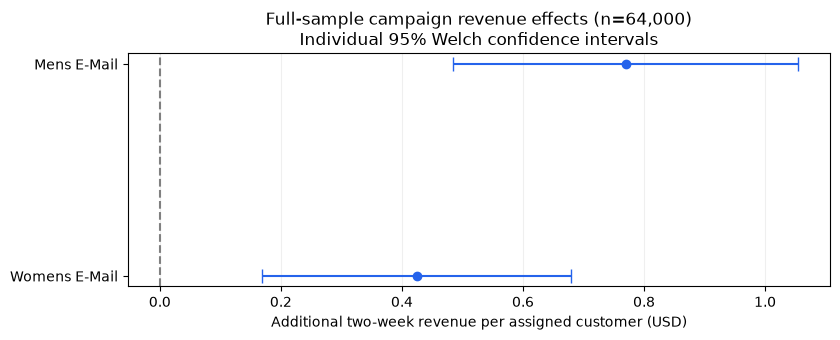

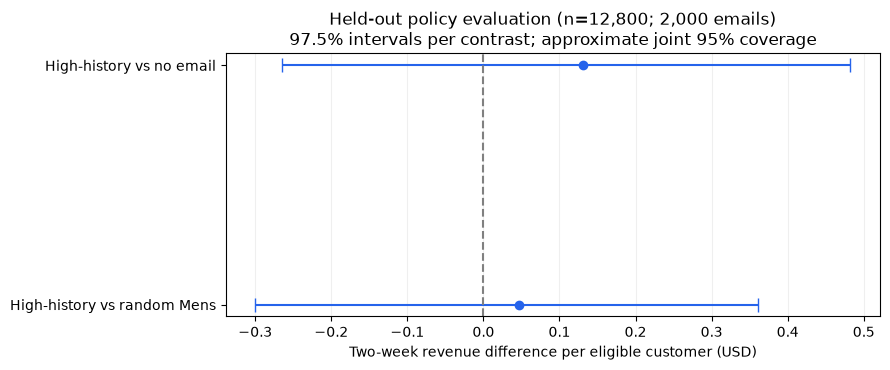

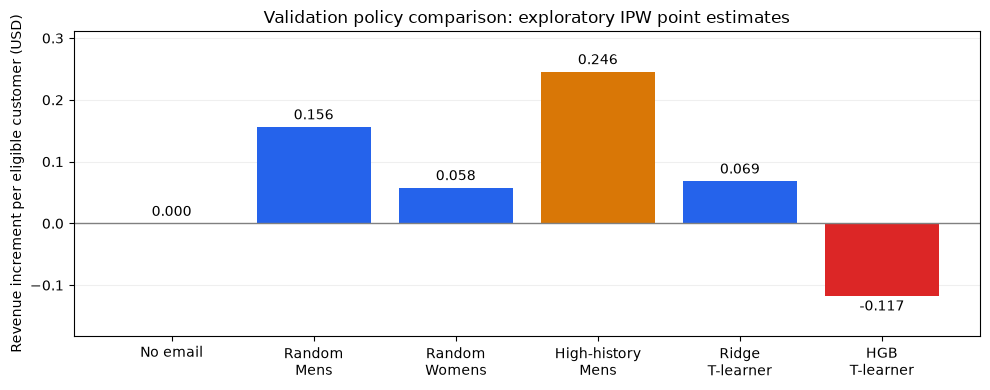

In [34]:
fig, ax = plt.subplots(figsize=(8.5, 3.5))
effects = full_primary["effect"]
ax.errorbar(effects, full_primary.index, xerr=[
    effects - full_primary["ci_low"],
    full_primary["ci_high"] - effects
], fmt="o", capsize=5, color="#2563eb")
ax.axvline(0, color="gray", linestyle="--")
ax.invert_yaxis()
ax.set_title("Full-sample campaign revenue effects (n=64,000)\nIndividual 95% Welch confidence intervals")
ax.set_xlabel("Additional two-week revenue per assigned customer (USD)")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "full_campaign_effects.png", dpi=220, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.8))
effects = test_policy_results["difference"]
labels = ["High-history vs no email", "High-history vs random Mens"]
ax.errorbar(effects, labels, xerr=[
    effects - test_policy_results["ci_low"],
    test_policy_results["ci_high"] - effects
], fmt="o", capsize=5, color="#2563eb")
ax.axvline(0, color="gray", linestyle="--")
ax.invert_yaxis()
ax.set_title("Held-out policy evaluation (n=12,800; 2,000 emails)\n97.5% intervals per contrast; approximate joint 95% coverage")
ax.set_xlabel("Two-week revenue difference per eligible customer (USD)")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "test_policy_comparison.png", dpi=220, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
values = validation_comparison["increment_vs_no_email"]
labels = ["No email", "Random\nMens", "Random\nWomens",
          "High-history\nMens", "Ridge\nT-learner", "HGB\nT-learner"]
colors = ["#64748b", "#2563eb", "#2563eb", "#d97706", "#2563eb", "#dc2626"]
bars = ax.bar(labels, values, color=colors)
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.axhline(0, color="gray", linewidth=1)
ax.set_title("Validation policy comparison: exploratory IPW point estimates")
ax.set_ylabel("Revenue increment per eligible customer (USD)")
ax.margins(y=0.18)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "validation_policy_comparison.png", dpi=220, bbox_inches="tight")
plt.show()

## Illustrative cost and margin scenarios

Actual campaign costs and contribution margins are unavailable. The following are explicitly assumed scenarios, not measured profit or current market prices.

Project the held-out mean differences to an illustrative batch of 64,000 eligible customers at the same 15.625% capacity (10,000 emails), assuming the held-out effect transfers to that batch. This is a projection, not realized revenue in the historical data.

Incremental contribution = assumed margin times projected revenue difference minus email cost times the difference in email counts. Against random Mens, both policies mail 10,000, so their mailing-cost difference is zero. Fixed platform and implementation costs and longer-term effects are outside these scenarios.

Transform the same held-out interval bounds with these fixed assumptions. Wide intervals remain wide; positive scenario point estimates are not established profitability.


In [35]:
scenario_population = 64_000
scenario_capacity = int(scenario_population * capacity_fraction)
scenario_rows = []
for comparison, result in test_policy_results.iterrows():
    extra_emails = scenario_capacity if comparison.endswith("No email") else 0
    for margin in [0.20, 0.40, 0.60]:
        for email_cost in [0.01, 0.05, 0.10]:
            cost_difference = extra_emails * email_cost
            factor = scenario_population * margin
            scenario_rows.append({
                "comparison": comparison,
                "eligible_customers": scenario_population,
                "target_emails": scenario_capacity,
                "assumed_margin": margin,
                "assumed_cost_per_email": email_cost,
                "projected_revenue_difference": result["difference"] * scenario_population,
                "projected_contribution_difference": result["difference"] * factor - cost_difference,
                "ci_low": result["ci_low"] * factor - cost_difference,
                "ci_high": result["ci_high"] * factor - cost_difference,
                "scenario_only": True
            })
business_scenarios = pd.DataFrame(scenario_rows)

base_contrast = test_policy_results.loc["High-history vs No email"]
break_even_rows = []
for margin in [0.20, 0.40, 0.60]:
    scale = scenario_population * margin / scenario_capacity
    break_even_rows.append({
        "assumed_margin": margin,
        "estimated_break_even_email_cost": base_contrast["difference"] * scale,
        "ci_low": base_contrast["ci_low"] * scale,
        "ci_high": base_contrast["ci_high"] * scale,
        "scenario_only": True
    })
break_even_scenarios = pd.DataFrame(break_even_rows)

display(business_scenarios.loc[
    (business_scenarios["assumed_margin"] == 0.40)
    & (business_scenarios["assumed_cost_per_email"] == 0.05),
    ["comparison", "projected_contribution_difference", "ci_low", "ci_high"]
].round(2))
display(break_even_scenarios.round(3))

,comparison,projected_contribution_difference,ci_low,ci_high
4,High-history vs No email,2843.36,-7272.62,11845.58
13,High-history vs Random Mens,1200.64,-7670.80,9234.76


,assumed_margin,estimated_break_even_email_cost,ci_low,ci_high,scenario_only
0,0.2,0.167,-0.339,0.617,True
1,0.4,0.334,-0.677,1.235,True
2,0.6,0.502,-1.016,1.852,True


## Reusable selected rule and reproducible exports

The selected rule has no fitted coefficients: rank pretreatment history, mail Mens to at most floor(N times 0.15625), and otherwise recommend no email. The module below returns recommendations only; it sends no messages.

Export aggregate tables, source-row split metadata and derived recommendations. Raw customer records remain excluded from the repository. A generated row number is an analysis-record locator, not a customer identity.


In [36]:
import importlib.metadata as metadata
import json
import platform
from src.policy import high_history_policy

assert high_history_policy(test["history"], capacity_fraction).equals(history_test_policy)

tables = {
    "full_campaign_summary": full_summary,
    "full_primary_revenue": full_primary,
    "development_campaign_summary": group_summary,
    "development_primary_revenue": revenue_tests,
    "development_bootstrap": bootstrap_check,
    "development_secondary_tests": secondary_tests,
    "development_revenue_decomposition": revenue_breakdown,
    "development_tail_distribution": spend_distribution,
    "development_capped_sensitivity": sensitivity,
    "development_adjusted_revenue": adjusted_comparison,
    "development_interaction_tests": interaction_tests,
    "development_newbie_summary": newbie_summary,
    "validation_policy_values": validation_comparison,
    "validation_selected_policy_intervals": validation_policy_ci,
    "test_policy_intervals": test_policy_results,
    "business_scenarios": business_scenarios,
    "break_even_scenarios": break_even_scenarios
}
for name, frame in tables.items():
    frame.to_csv(OUTPUT_DIR / (name + ".csv"), index=True)

split_labels = pd.Series(index=email_clean.index, dtype="object", name="split")
split_labels.loc[train.index] = "train"
split_labels.loc[validation.index] = "validation"
split_labels.loc[test.index] = "test"
split_labels.rename_axis("source_row_index").to_csv(OUTPUT_DIR / "split_manifest.csv")

recommendations = pd.DataFrame({
    "recommendation": history_test_policy
}).rename_axis("source_row_index")
recommendations.to_csv(OUTPUT_DIR / "test_recommendations.csv")

protocol = {
    "selection_stage": "validation",
    "criterion": "maximum mean IPW policy revenue",
    "selected_policy": "High-history Mens",
    "feature": "pretreatment history",
    "action": "Mens E-Mail",
    "capacity_fraction": capacity_fraction,
    "tie_break": "first occurrence in input row order",
    "candidate_set": list(validation_comparison.index),
    "test_comparisons": list(test_policy_results.index),
    "test_interval_level_per_comparison": test_ci_level,
    "approximate_joint_test_interval_level": 0.95,
    "bootstrap_replicates": 10_000,
    "bootstrap_seed": 42,
    "allocation_weights": "split-specific fixed arm fractions n_arm / N",
    "no_test_outcome_based_retuning": True
}
(OUTPUT_DIR / "selected_policy.json").write_text(
    json.dumps(protocol, indent=2), encoding="utf-8"
)

packages = ["pandas", "numpy", "scipy", "statsmodels", "scikit-learn",
            "matplotlib", "nbformat", "nbclient", "ipykernel"]
environment = {
    "python": platform.python_version(),
    "packages": {name: metadata.version(name) for name in packages}
}
(OUTPUT_DIR / "environment.json").write_text(
    json.dumps(environment, indent=2), encoding="utf-8"
)

def records(frame):
    return json.loads(frame.reset_index().to_json(orient="records", double_precision=15))

results = {
    "data_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "rows": len(email_clean),
    "development_rows": len(train_val),
    "split_sizes": {"train": len(train), "validation": len(validation), "test": len(test)},
    "full_primary": records(full_primary),
    "full_summary": records(full_summary),
    "validation_policies": records(validation_comparison),
    "test_policy_intervals": records(test_policy_results),
    "test_policy_values": {
        "No email": float(no_email_test_scores.mean()),
        "Random Mens E-Mail": float(random_mens_test_scores.mean()),
        "High-history Mens": float(history_test_scores.mean())
    },
    "source_matching_extra_rows": int(email.duplicated().sum()),
    "srm_p": float(srm_p),
    "coherence_flags": {str(k): int(v) for k, v in checks.items()},
    "capped_sensitivity_threshold": float(cap),
    "capped_sensitivity_rows": int((train_val["spend"] > cap).sum()),
    "protocol": protocol,
    "source_notebook_sha256": "1ff458b3dcf422beb423085d8f831cba1d1747874510af849be88a88b7a47eae"
}
(OUTPUT_DIR / "results.json").write_text(
    json.dumps(results, indent=2, allow_nan=False), encoding="utf-8"
)
print("Exported aggregate results, split metadata, recommendations and protocol.")

Exported aggregate results, split metadata, recommendations and protocol.


## Conclusions and limits

- Both campaigns increase mean two-week revenue versus no email in the final full-sample primary analysis.
- The validation-selected high-history Mens rule has a positive test point estimate, but its two adjusted-coverage intervals include zero. Added targeting value is not established; this does not establish zero effect or equivalence.
- The two fitted T-learners did not improve on the highest validation benchmark. Avoid claiming personalization creates value merely because predictions differ by customer.
- The historical two-week data do not establish long-term retention, profit, contemporary campaign performance or individual causal effects.
- No persistent IDs, assignment logs, delivery information or timestamps are available to verify identity independence, original randomization, compliance, interference or follow-up.
- Costs and margins in the scenario tables are assumptions. Raw data are not redistributed.

The next practical step would be a new randomized comparison of the fixed targeting rule against a uniformly random Mens mailing, with an outcome horizon and precision target chosen in advance.
